This test is on
1. i.i.d. rayleigh fading channel
2. 4*4 MIMO channel
3. 1000 symbols per channel
4. total of 1000 channels

ver 11.24.04.35


In [1]:
"""
DONT RUN THIS CODE BLOCK WHEN USING LOCAL COMPUTER
THIS IS ONLY FOR GOOGLE COLAB
"""
!cd /content
!rm -rf EE_MIMO_PROJECT
!git clone https://github.com/billlllllllly/EE_MIMO_PROJECT.git
# load the whole repo
%cd EE_MIMO_PROJECT
%pip install -r requirements.txt
# change the dir
!ls
# just for checking that the current folder is correct

Cloning into 'EE_MIMO_PROJECT'...
remote: Enumerating objects: 422, done.
remote: Counting objects: 100% (422/422), done.
remote: Compressing objects: 100% (303/303), done.
remote: Total 422 (delta 183), reused 270 (delta 100), pack-reused 0 (from 0)
Receiving objects: 100% (422/422), 7.99 MiB | 22.72 MiB/s, done.
Resolving deltas: 100% (183/183), done.
/content/EE_MIMO_PROJECT
NYCU_scene  requirements.txt  simulation_results  src


In [2]:
# import models
from src.models.MAP import MAP
from src.models.MMSE import MMSE
from src.models.SIC import SIC
from src.models.partialMAP import partialMAP

In [17]:
# mimo settings
import torch
from src.channel.rayleighfading import rayleighfading
BLOCKS = 1000
SYMBOLS_PER_CHANNEL = 10
# total of (SYMBOLS_PER_CHANNEL * BLOCKS) symbols are transmitted
NT = 2
NR = 2
SNR_DB = list(range(0, 21, 2))
MODULATION = "QPSK"

def generateChannel(NR, NT):
    return rayleighfading(NR=NR, NT=NT)

qpsk = torch.tensor([-1-1j, -1+1j, 1+1j, 1-1j], dtype=torch.complex128) / 2**0.5
symbol_qpsk = torch.tensor([[0, 0], [1, 0], [1, 1], [0, 1]])
bpsk = torch.tensor([-1, 1], dtype=torch.complex128) / 2**0.5
symbol_bpsk = torch.tensor([[0], [1]])

In [18]:
import inspect

print(inspect.getfile(partialMAP))
print(inspect.signature(partialMAP))

/content/EE_MIMO_PROJECT/src/models/partialMAP.py
(*, verbose=True, csv_log_dir=None)


running channel number 0
running channel number 10
running channel number 20
running channel number 30
running channel number 40
running channel number 50
running channel number 60
running channel number 70
running channel number 80
running channel number 90
running channel number 100
running channel number 110
running channel number 120
running channel number 130
running channel number 140
running channel number 150
running channel number 160
running channel number 170
running channel number 180
running channel number 190
running channel number 200
running channel number 210
running channel number 220
running channel number 230
running channel number 240
running channel number 250
running channel number 260
running channel number 270
running channel number 280
running channel number 290
running channel number 300
running channel number 310
running channel number 320
running channel number 330
running channel number 340
running channel number 350
running channel number 360
running chan

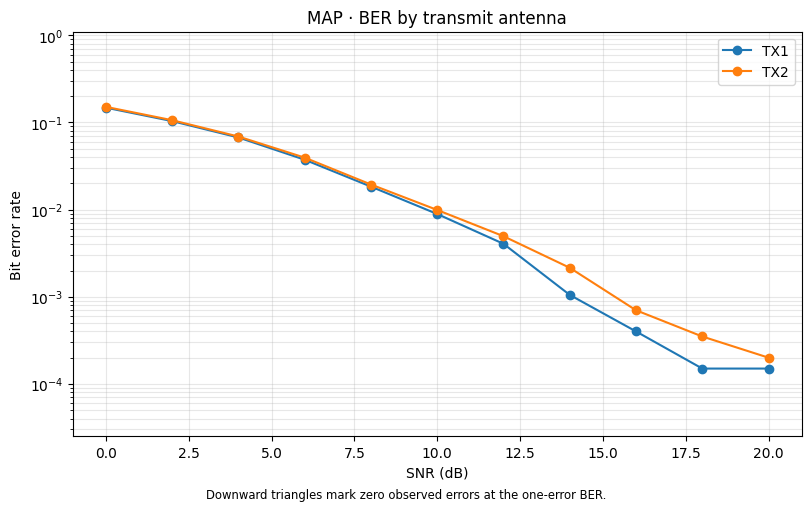

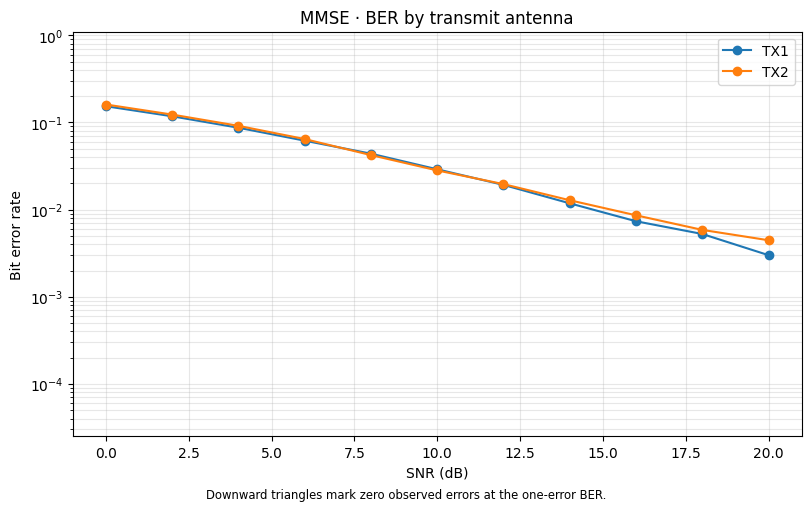

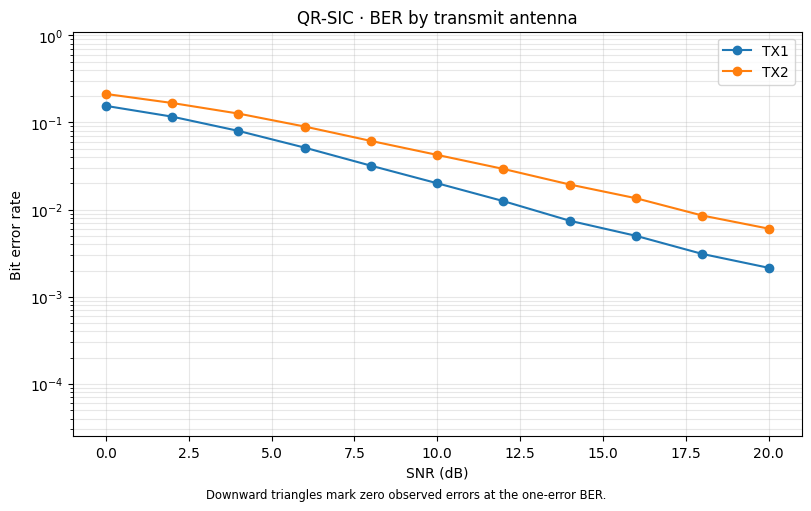

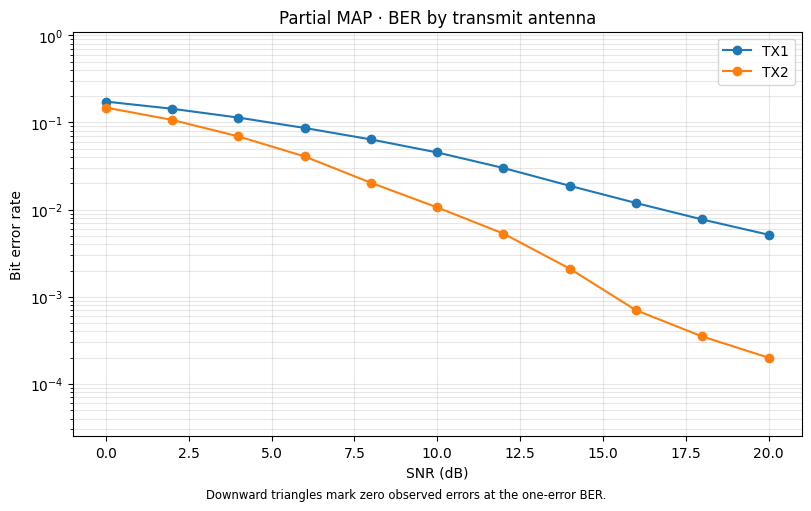

40,000 bits per SNR
SNR (dB)            MAP          MMSE        QR-SIC   Partial MAP
       0         0.1493         0.157        0.1835        0.1608
       2         0.1048        0.1203        0.1418        0.1252
       4        0.06805       0.08918        0.1032       0.09137
       6         0.0384        0.0631       0.07055       0.06355
       8        0.01887         0.043       0.04662       0.04205
      10         0.0094       0.02857       0.03122       0.02792
      12         0.0045        0.0194       0.02088       0.01765
      14         0.0016        0.0123       0.01342       0.01043
      16        0.00055      0.007975       0.00925        0.0063
      18        0.00025       0.00555      0.005825      0.004025
      20       0.000175      0.003725        0.0041      0.002675


In [19]:
from pathlib import Path
from tempfile import mkdtemp

from src.channel.testbench import Testbench

# Use a fresh directory because Partial MAP appends rows to its CSV files.
pmap_log_dir = Path(mkdtemp(prefix="rayleigh_pmap_"))
models = {
    "MAP": MAP(),
    "MMSE": MMSE(),
    "QR-SIC": SIC(),
    "Partial MAP": partialMAP(verbose=False, csv_log_dir=pmap_log_dir),
}

if MODULATION == "QPSK":
    SYMBOL = symbol_qpsk
    BITLABEL = qpsk
else:
    SYMBOL = symbol_bpsk
    BITLABEL = bpsk

bench = Testbench(models, BITLABEL, SYMBOL, SYMBOLS_PER_CHANNEL, SNR_DB)
csi = torch.stack([generateChannel(NR=NR, NT=NT) for _ in range(BLOCKS)])
ERROR_CSV = "rayleigh_bit_errors.csv"
ber, bits_per_snr = bench.run(csi, csv_path=ERROR_CSV, plot_antenna_ber=True)

print(f"{bits_per_snr:,} bits per SNR")
print("SNR (dB)   " + "  ".join(f"{name:>12}" for name in models))
for snr, row in zip(SNR_DB, ber):
    print(f"{snr:8g}   " + "  ".join(f"{value:12.4g}" for value in row))

In [16]:
# # Save all Partial MAP layer CSVs as a zip directly to Google Drive root.
# import shutil
# from zipfile import ZIP_DEFLATED, ZipFile

# from google.colab import drive

# drive.mount("/content/drive")

# archive_path = pmap_log_dir / "rayleigh_pmap_layers.zip"
# with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
#     for layer in range(NT):
#         layer_csv = pmap_log_dir / f"layer_{layer}.csv"
#         archive.write(layer_csv, arcname=layer_csv.name)

# drive_path = "/content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/rayleigh_pmap_layers.zip"
# shutil.copy(archive_path, drive_path)
# print(f"Saved Partial MAP CSV archive to {drive_path}")

# Save all Partial MAP layer CSVs directly to Google Drive root (no zip).
import shutil
import os
from google.colab import drive

drive.mount("/content/drive")
out_dir = "/content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/" + f"rayleigh_{NR}_by_{NT}_{MODULATION}/"
os.makedirs(out_dir, exist_ok=True)

for layer in range(NT):
    csv_name = f"layer_{layer}.csv"
    layer_csv = pmap_log_dir / csv_name
    out_path = out_dir + csv_name
    shutil.copy(layer_csv, out_path)
    print(f"Saved {out_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/rayleigh_4_by_4_BPSK/layer_0.csv
Saved /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/rayleigh_4_by_4_BPSK/layer_1.csv
Saved /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/rayleigh_4_by_4_BPSK/layer_2.csv
Saved /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/rayleigh_4_by_4_BPSK/layer_3.csv


Downward triangles: zero observed errors, shown at 1 / bits per SNR.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

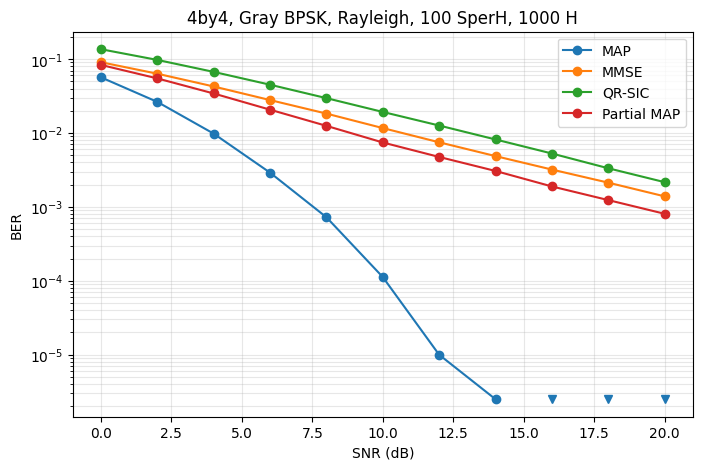

In [9]:
import matplotlib.pyplot as plt
import numpy as np

snr_db = np.asarray(SNR_DB)
fig, ax = plt.subplots(figsize=(8, 5))

for j, name in enumerate(models):
    points = ber[:, j]
    line, = ax.semilogy(
        snr_db, np.where(points > 0, points, np.nan), "o-", label=name
    )

    zero = points == 0
    if zero.any():
        ax.semilogy(
            snr_db[zero],
            np.full(zero.sum(), 1 / bits_per_snr),
            "v",
            color=line.get_color(),
        )

TITLE = f"{NT}by{NR}, Gray BPSK, Rayleigh, {SYMBOLS_PER_CHANNEL} SperH, {BLOCKS} H"
ax.set(xlabel="SNR (dB)", ylabel="BER",
       title=TITLE)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
print("Downward triangles: zero observed errors, shown at 1 / bits per SNR.")

plt.savefig(f'{TITLE}.png', dpi=300, bbox_inches='tight')
try:
    from google.colab import files
except ImportError:
    pass
else:
    files.download(ERROR_CSV)
    files.download(f'{TITLE}.png')

plt.show()